# RAJUK Heterogeneous Ensemble — Random Forest v3

This notebook keeps the subject-safe ResNet50 input pipeline from f2 and improves the classifier with a heterogeneous ensemble:

- bootstrapped Random Forest;
- bootstrapped Extra Trees;
- balanced multinomial logistic regression;
- balanced RBF-SVM;
- validation-selected soft-voting weights and class probability multipliers.

The test set is never used for selecting models, voting weights, or class multipliers. Run every cell from top to bottom.

## 1. Load the f2 input and CUDA feature pipeline

The setup, subject split, ResNet50 embedding extractor, and source-distribution code are reused directly from the supplied f2 notebook. Existing f2 feature caches are reused, so the images normally do not need to be embedded again. The f2 model-training and report cells are not executed.

In [3]:
import json
from pathlib import Path
from IPython.display import display

ROOT_HINT = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd().parent.parent.parent, ROOT_HINT]
bootstrap_root = next(
    (path.resolve() for path in root_candidates
     if (path / 'Random_Forest' / 'f2' / 'rajuk_random_forest_v2.ipynb').exists()),
    None,
)
if bootstrap_root is None:
    raise FileNotFoundError('Could not locate Random_Forest/f2/rajuk_random_forest_v2.ipynb')

BASE_NOTEBOOK_PATH = bootstrap_root / 'Random_Forest' / 'f2' / 'rajuk_random_forest_v2.ipynb'
with open(BASE_NOTEBOOK_PATH, 'r', encoding='utf-8') as file:
    base_notebook = json.load(file)

def run_base_code_cell(index):
    source = ''.join(base_notebook['cells'][index]['source'])
    exec(compile(source, f'{BASE_NOTEBOOK_PATH.name}:cell_{index}', 'exec'), globals())

# Imports/configuration, then redirect all new artifacts into f3.
run_base_code_cell(2)
F2_FEATURE_CACHE_DIR = FEATURE_CACHE_DIR
OUTPUT_DIR = PROJECT_ROOT / 'Random_Forest' / 'f3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE_DIR = F2_FEATURE_CACHE_DIR
MODEL_PATH = OUTPUT_DIR / 'rajuk_random_forest_ensemble_v3.pkl'
TEST_MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_ensemble_v3.csv'
VAL_MISCLASSIFIED_CSV = OUTPUT_DIR / 'val_misclassified_ensemble_v3.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_ensemble_v3.png'

# Labels/split, cached CUDA embeddings, and distribution summary.
run_base_code_cell(4)
run_base_code_cell(6)

def repair_nonfinite_embeddings(X, paths, split_name):
    """Re-embed damaged rows in full FP32, then apply a finite fallback."""
    X = np.asarray(X, dtype=np.float32).copy()
    damaged_indices = np.flatnonzero(~np.isfinite(X).all(axis=1))
    if len(damaged_indices):
        print(f'  {split_name}: repairing {len(damaged_indices):,} non-finite embedding rows in FP32')
        repair_batch_size = 16
        for start in range(0, len(damaged_indices), repair_batch_size):
            batch_indices = damaged_indices[start:start + repair_batch_size]
            tensors = []
            for index in batch_indices:
                with Image.open(paths[index]) as image:
                    tensors.append(image_transform(image.convert('RGB')))
            images = torch.stack(tensors).to(DEVICE)
            # Deliberately do not use FP16 autocast here: overflow during cached
            # extraction is the usual cause of an entirely NaN embedding row.
            with torch.inference_mode():
                repaired = resnet_backbone(images.float())
                repaired = F.normalize(repaired.float(), p=2, dim=1)
            X[batch_indices] = repaired.cpu().numpy().astype(np.float32)
    return X, damaged_indices

X_train, repaired_train_rows = repair_nonfinite_embeddings(X_train, train_paths, 'train')
X_val, repaired_val_rows = repair_nonfinite_embeddings(X_val, val_paths, 'validation')
X_test, repaired_test_rows = repair_nonfinite_embeddings(X_test, test_paths, 'test')

# Final train-derived median fallback protects against any image that remains
# non-finite even after FP32 re-embedding. Validation/test statistics are not used.
finite_train = np.where(np.isfinite(X_train), X_train, np.nan)
feature_fill_values = np.nanmedian(finite_train, axis=0)
feature_fill_values = np.nan_to_num(feature_fill_values, nan=0.0, posinf=0.0, neginf=0.0)
def apply_finite_fallback(X):
    bad = ~np.isfinite(X)
    if bad.any():
        X = X.copy()
        rows, columns = np.where(bad)
        X[rows, columns] = feature_fill_values[columns]
    return X
X_train = apply_finite_fallback(X_train)
X_val = apply_finite_fallback(X_val)
X_test = apply_finite_fallback(X_test)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
print('Finite-feature check passed for train, validation, and test.')

run_base_code_cell(8)

REFERENCE_F2_IMAGE_ACCURACY = 0.6243
REFERENCE_F2_IMAGE_MACRO_F1 = 0.3257
REFERENCE_F2_REAL_ACCURACY = 0.5867
REFERENCE_F2_REAL_MACRO_F1 = 0.4644
print(f'\nf3 output directory : {OUTPUT_DIR}')
print(f'Reused feature cache : {FEATURE_CACHE_DIR}')

Project root       : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files
Feature device     : cuda
CUDA GPU           : NVIDIA GeForce GTX 1650
PyTorch CUDA build : 12.4
Backbone           : resnet50 (frozen, ImageNet pretrained)
Tree training      : CPU (all available cores through n_jobs=-1)
Output directory   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2
Loaded labels    : 372 from Real ML_DataSet.csv
Augmented images : 5,968
Real images      : 373
Skipped files    : 17

Training (full, used as-is): 4,420 images from 259 subjects
  negative  : 2,720
  moderate  : 969
  positive  : 731

Validation: 646 images from 38 subjects
  negative  : 408
  moderate  : 136
  positive  : 102

Test: 1,275 images from 75 subjects
  negative  : 782
  moderate  : 289
  positive  : 204
  train: loaded 4,420 cached embeddings
  validation: loaded 646 cached em

,class,real,augmented,total_used,sklearn_weight
0,negative,160,2560,2720,0.542
1,moderate,57,912,969,1.520
2,positive,43,688,731,2.016


Total training images used: 4,420 (v1 used only 2,100).
Balancing strategy        : class_weight="balanced_subsample" (no data discarded).

f3 output directory : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f3
Reused feature cache : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\feature_cache


## 2. Train diverse base learners

Tree ensembles capture nonlinear feature interactions, while logistic regression and the RBF-SVM provide different decision boundaries. Diversity is essential—averaging nearly identical forests alone did not improve f2.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

CLASS_WEIGHT = {0: 1.0, 1: 2.15, 2: 2.35}
BASE_CONFIGS = {
    'rf': {
        'label': 'Random Forest',
        'model': RandomForestClassifier(
            n_estimators=750, criterion='entropy', max_depth=None,
            min_samples_leaf=1, max_features='sqrt', bootstrap=True,
            max_samples=0.90, oob_score=True, class_weight=CLASS_WEIGHT,
            random_state=SEED + 101, n_jobs=-1,
        ),
    },
    'et': {
        'label': 'Extra Trees',
        'model': ExtraTreesClassifier(
            n_estimators=750, criterion='entropy', max_depth=None,
            min_samples_leaf=1, max_features='sqrt', bootstrap=True,
            max_samples=0.90, oob_score=True, class_weight=CLASS_WEIGHT,
            random_state=SEED + 202, n_jobs=-1,
        ),
    },
    'lr': {
        'label': 'Logistic Regression',
        'model': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LogisticRegression(
                C=0.20, class_weight='balanced', max_iter=3000,
                solver='lbfgs', random_state=SEED + 303,
            )),
        ]),
    },
    'svm': {
        'label': 'RBF-SVM',
        'model': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', SVC(
                C=1.5, kernel='rbf', gamma='scale', probability=True,
                class_weight='balanced', cache_size=2048,
                random_state=SEED + 404,
            )),
        ]),
    },
}

def aggregate_probabilities_by_subject(probabilities, labels, groups):
    subject_labels, subject_probabilities = [], []
    for group in np.unique(groups):
        mask = groups == group
        subject_labels.append(int(labels[mask][0]))
        subject_probabilities.append(probabilities[mask].mean(axis=0))
    return np.asarray(subject_labels), np.stack(subject_probabilities)

def calculate_metrics(labels, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        'accuracy': accuracy_score(labels, predictions),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
        'log_loss': log_loss(labels, probabilities, labels=np.arange(len(CLASS_NAMES))),
    }

base_models = {}
base_val_probabilities = {}
base_rows = []
for key, config in BASE_CONFIGS.items():
    print(f'Fitting {config["label"]} ...')
    model = config['model']
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_val)
    base_models[key] = model
    base_val_probabilities[key] = probabilities
    subject_y, subject_probability = aggregate_probabilities_by_subject(
        probabilities, y_val, val_groups
    )
    row = {'key': key, 'model': config['label']}
    row.update({f'image_{name}': value for name, value in calculate_metrics(y_val, probabilities).items()})
    row.update({f'subject_{name}': value for name, value in calculate_metrics(subject_y, subject_probability).items()})
    if hasattr(model, 'oob_score_'):
        row['oob_accuracy'] = model.oob_score_
    base_rows.append(row)

base_results_df = pd.DataFrame(base_rows).sort_values(
    ['subject_macro_f1', 'subject_accuracy'], ascending=False
).reset_index(drop=True)
display(base_results_df)
base_results_df.to_csv(OUTPUT_DIR / 'base_model_validation_results.csv', index=False)

Fitting Random Forest ...
Fitting Extra Trees ...
Fitting Logistic Regression ...
Fitting RBF-SVM ...


d:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\.venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,key,model,image_accuracy,image_balanced_accuracy,image_macro_f1,image_log_loss,subject_accuracy,subject_balanced_accuracy,subject_macro_f1,subject_log_loss,oob_accuracy
0,lr,Logistic Regression,0.605263,0.450163,0.447274,1.475939,0.605263,0.472222,0.491209,1.166601,NaN
1,rf,Random Forest,0.631579,0.333333,0.258065,0.854245,0.631579,0.333333,0.258065,0.851854,0.974208
2,et,Extra Trees,0.631579,0.333333,0.258065,0.847585,0.631579,0.333333,0.258065,0.845772,0.974887
3,svm,RBF-SVM,0.543344,0.305556,0.274456,1.305324,0.526316,0.277778,0.233918,1.172983,NaN


## 3. Validation-selected weighted soft voting

The search requires at least two active models and at least one bagged-tree component. It jointly selects voting weights and mild class-probability multipliers. The score emphasizes accuracy while retaining macro-F1 and balanced accuracy to avoid the all-negative failure mode.

In [5]:
MODEL_KEYS = list(BASE_CONFIGS)
stacked_val_probabilities = np.stack([base_val_probabilities[key] for key in MODEL_KEYS])
validation_real_mask = np.asarray([not is_augmented_path(path) for path in val_paths])

def apply_class_multipliers(probabilities, multipliers):
    adjusted = np.asarray(probabilities, dtype=np.float64) * np.asarray(multipliers)[None, :]
    return adjusted / np.maximum(adjusted.sum(axis=1, keepdims=True), 1e-12)

def combined_selection_score(image_metrics, subject_metrics, real_metrics):
    return (
        0.35 * image_metrics['accuracy']
        + 0.25 * subject_metrics['accuracy']
        + 0.15 * real_metrics['accuracy']
        + 0.15 * subject_metrics['macro_f1']
        + 0.10 * subject_metrics['balanced_accuracy']
    )

rng = np.random.default_rng(SEED + 3000)
weight_candidates = [
    np.array([0.25, 0.25, 0.25, 0.25]),
    np.array([0.35, 0.25, 0.25, 0.15]),
    np.array([0.25, 0.20, 0.35, 0.20]),
    np.array([0.20, 0.20, 0.25, 0.35]),
]
while len(weight_candidates) < 1200:
    candidate = rng.dirichlet(np.array([1.5, 1.5, 1.2, 1.2]))
    if (candidate[:2].sum() >= 0.20) and (np.sum(candidate >= 0.10) >= 2):
        weight_candidates.append(candidate)

class_multiplier_candidates = [
    np.array([1.00, 1.00, 1.00]),
    np.array([1.00, 1.10, 1.10]),
    np.array([1.00, 1.20, 1.20]),
    np.array([1.00, 1.30, 1.30]),
    np.array([1.00, 1.15, 1.30]),
    np.array([1.00, 1.30, 1.15]),
    np.array([1.00, 1.40, 1.20]),
    np.array([1.00, 1.20, 1.40]),
]

selection_rows = []
best_selection = None
for weights in weight_candidates:
    blended = np.average(stacked_val_probabilities, axis=0, weights=weights)
    for multipliers in class_multiplier_candidates:
        adjusted = apply_class_multipliers(blended, multipliers)
        subject_y, subject_probability = aggregate_probabilities_by_subject(
            adjusted, y_val, val_groups
        )
        image_metrics = calculate_metrics(y_val, adjusted)
        subject_metrics = calculate_metrics(subject_y, subject_probability)
        real_metrics = calculate_metrics(
            y_val[validation_real_mask], adjusted[validation_real_mask]
        )
        score = combined_selection_score(image_metrics, subject_metrics, real_metrics)
        row = {
            'score': score, 'weights': weights.copy(), 'multipliers': multipliers.copy(),
            'image_accuracy': image_metrics['accuracy'],
            'subject_accuracy': subject_metrics['accuracy'],
            'real_accuracy': real_metrics['accuracy'],
            'subject_macro_f1': subject_metrics['macro_f1'],
            'subject_balanced_accuracy': subject_metrics['balanced_accuracy'],
            'subject_log_loss': subject_metrics['log_loss'],
        }
        selection_rows.append(row)
        if best_selection is None or (
            row['score'], row['subject_macro_f1'], row['real_accuracy'], -row['subject_log_loss']
        ) > (
            best_selection['score'], best_selection['subject_macro_f1'],
            best_selection['real_accuracy'], -best_selection['subject_log_loss']
        ):
            best_selection = row

selected_weights = np.asarray(best_selection['weights'])
selected_class_multipliers = np.asarray(best_selection['multipliers'])
val_probabilities = apply_class_multipliers(
    np.average(stacked_val_probabilities, axis=0, weights=selected_weights),
    selected_class_multipliers,
)
val_predictions = val_probabilities.argmax(axis=1)

selection_results_df = pd.DataFrame(selection_rows).sort_values(
    ['score', 'subject_macro_f1', 'real_accuracy'], ascending=False
).head(30)
selection_results_df['weights'] = selection_results_df['weights'].apply(
    lambda values: dict(zip(MODEL_KEYS, np.round(values, 4)))
)
selection_results_df['multipliers'] = selection_results_df['multipliers'].apply(
    lambda values: dict(zip(CLASS_NAMES, np.round(values, 3)))
)
display(selection_results_df)
selection_results_df.to_csv(OUTPUT_DIR / 'ensemble_weight_search_top30.csv', index=False)

print('\nSELECTED ENSEMBLE')
print('-' * 65)
for key, weight in zip(MODEL_KEYS, selected_weights):
    print(f'{BASE_CONFIGS[key]["label"]:<24}: {weight:.4f}')
print(f'Class multipliers       : {dict(zip(CLASS_NAMES, selected_class_multipliers))}')
print(f'Validation image acc    : {accuracy_score(y_val, val_predictions):.4f}')
print(f'Validation image macroF1: {f1_score(y_val, val_predictions, average="macro"):.4f}')

# Cache tree-member predictions for the bias-variance graph before freeing selection models.
bias_member_probabilities, bias_member_weights = [], []
for model_key, model_weight in zip(MODEL_KEYS[:2], selected_weights[:2]):
    if model_weight <= 0:
        continue
    model = base_models[model_key]
    tree_count = min(MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE, len(model.estimators_))
    tree_indices = np.linspace(0, len(model.estimators_) - 1, tree_count, dtype=int)
    for tree_index in tree_indices:
        tree = model.estimators_[tree_index]
        raw = tree.predict_proba(X_val)
        aligned = np.zeros((len(X_val), len(CLASS_NAMES)), dtype=np.float64)
        for probability_column, class_index in enumerate(tree.classes_.astype(int)):
            aligned[:, class_index] = raw[:, probability_column]
        bias_member_probabilities.append(
            apply_class_multipliers(aligned, selected_class_multipliers)
        )
        bias_member_weights.append(float(model_weight) / tree_count)
bias_member_probabilities = np.stack(bias_member_probabilities)
bias_member_weights = np.asarray(bias_member_weights)
bias_member_weights /= bias_member_weights.sum()

# BASE_CONFIGS initially holds the fitted objects too. Replace them with unfitted
# clones so all selection models—including SVM support vectors—can be released.
from sklearn.base import clone
for key in MODEL_KEYS:
    BASE_CONFIGS[key]['model'] = clone(BASE_CONFIGS[key]['model'])
del base_models, base_val_probabilities, stacked_val_probabilities
gc.collect()

,score,weights,multipliers,image_accuracy,subject_accuracy,real_accuracy,subject_macro_f1,subject_balanced_accuracy,subject_log_loss
8543,0.600287,"{'rf': 0.0154, 'et': 0.5898, 'lr': 0.3876, 'sv...","{'negative': 1.0, 'moderate': 1.2, 'positive':...",0.622291,0.657895,0.605263,0.514815,0.5,0.815552
4066,0.598662,"{'rf': 0.0908, 'et': 0.4166, 'lr': 0.4849, 'sv...","{'negative': 1.0, 'moderate': 1.2, 'positive':...",0.617647,0.657895,0.605263,0.514815,0.5,0.813762
8435,0.598662,"{'rf': 0.3216, 'et': 0.2491, 'lr': 0.4089, 'sv...","{'negative': 1.0, 'moderate': 1.3, 'positive':...",0.617647,0.657895,0.605263,0.514815,0.5,0.813980
2779,0.598120,"{'rf': 0.214, 'et': 0.3361, 'lr': 0.4186, 'svm...","{'negative': 1.0, 'moderate': 1.3, 'positive':...",0.616099,0.657895,0.605263,0.514815,0.5,0.814606
5313,0.598120,"{'rf': 0.0701, 'et': 0.3554, 'lr': 0.5668, 'sv...","{'negative': 1.0, 'moderate': 1.1, 'positive':...",0.616099,0.657895,0.605263,0.514815,0.5,0.823583
6851,0.598120,"{'rf': 0.3512, 'et': 0.2278, 'lr': 0.4182, 'sv...","{'negative': 1.0, 'moderate': 1.3, 'positive':...",0.616099,0.657895,0.605263,0.514815,0.5,0.812870
9154,0.598120,"{'rf': 0.0583, 'et': 0.4534, 'lr': 0.4681, 'sv...","{'negative': 1.0, 'moderate': 1.2, 'positive':...",0.616099,0.657895,0.605263,0.514815,0.5,0.814107
4618,0.597578,"{'rf': 0.1255, 'et': 0.362, 'lr': 0.4925, 'svm...","{'negative': 1.0, 'moderate': 1.2, 'positive':...",0.614551,0.657895,0.605263,0.514815,0.5,0.815894
8443,0.597578,"{'rf': 0.2534, 'et': 0.3076, 'lr': 0.42, 'svm'...","{'negative': 1.0, 'moderate': 1.3, 'positive':...",0.614551,0.657895,0.605263,0.514815,0.5,0.813777
2409,0.597036,"{'rf': 0.2492, 'et': 0.1833, 'lr': 0.5605, 'sv...","{'negative': 1.0, 'moderate': 1.1, 'positive':...",0.613003,0.657895,0.605263,0.514815,0.5,0.823218



SELECTED ENSEMBLE
-----------------------------------------------------------------
Random Forest           : 0.0154
Extra Trees             : 0.5898
Logistic Regression     : 0.3876
RBF-SVM                 : 0.0072
Class multipliers       : {'negative': np.float64(1.0), 'moderate': np.float64(1.2), 'positive': np.float64(1.4)}
Validation image acc    : 0.6223
Validation image macroF1: 0.4481


24

## 4. Refit the selected ensemble and evaluate the untouched test set

In [6]:
from sklearn.base import clone

X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])
trainval_groups = np.concatenate([train_groups, val_groups])

final_models = {}
for key, weight in zip(MODEL_KEYS, selected_weights):
    if weight < 0.01:
        continue
    print(f'Final fit: {BASE_CONFIGS[key]["label"]} (weight={weight:.4f})')
    model = clone(BASE_CONFIGS[key]['model'])
    model.fit(X_trainval, y_trainval)
    final_models[key] = model

active_keys = [key for key in MODEL_KEYS if key in final_models]
active_weights = np.asarray([selected_weights[MODEL_KEYS.index(key)] for key in active_keys])
active_weights /= active_weights.sum()

def ensemble_predict_proba(models, keys, weights, X, class_multipliers):
    probabilities = np.average(
        np.stack([models[key].predict_proba(X) for key in keys]), axis=0, weights=weights
    )
    return apply_class_multipliers(probabilities, class_multipliers)

train_probabilities = ensemble_predict_proba(
    final_models, active_keys, active_weights, X_trainval, selected_class_multipliers
)
test_probabilities = ensemble_predict_proba(
    final_models, active_keys, active_weights, X_test, selected_class_multipliers
)
train_predictions = train_probabilities.argmax(axis=1)
test_predictions = test_probabilities.argmax(axis=1)

test_metrics = calculate_metrics(y_test, test_probabilities)
test_subject_y, test_subject_probabilities = aggregate_probabilities_by_subject(
    test_probabilities, y_test, test_groups
)
test_subject_metrics = calculate_metrics(test_subject_y, test_subject_probabilities)
test_real_mask = np.asarray([not is_augmented_path(path) for path in test_paths])
test_real_y = y_test[test_real_mask]
test_real_probabilities = test_probabilities[test_real_mask]
test_real_predictions = test_predictions[test_real_mask]
test_real_metrics = calculate_metrics(test_real_y, test_real_probabilities)

print('\nFINAL TEST METRICS')
print('=' * 68)
print(f'Image accuracy          : {test_metrics["accuracy"]:.4f}')
print(f'Image balanced accuracy : {test_metrics["balanced_accuracy"]:.4f}')
print(f'Image macro-F1          : {test_metrics["macro_f1"]:.4f}')
print(f'Image log loss          : {test_metrics["log_loss"]:.4f}')
print(f'Subject accuracy        : {test_subject_metrics["accuracy"]:.4f}')
print(f'Subject macro-F1        : {test_subject_metrics["macro_f1"]:.4f}')
print(f'Real-only accuracy      : {test_real_metrics["accuracy"]:.4f}')
print(f'Real-only macro-F1      : {test_real_metrics["macro_f1"]:.4f}')
print('-' * 68)
print(f'Image accuracy vs f2    : {test_metrics["accuracy"] - REFERENCE_F2_IMAGE_ACCURACY:+.4f}')
print(f'Image macro-F1 vs f2    : {test_metrics["macro_f1"] - REFERENCE_F2_IMAGE_MACRO_F1:+.4f}')
print(f'Real accuracy vs f2     : {test_real_metrics["accuracy"] - REFERENCE_F2_REAL_ACCURACY:+.4f}')
print(f'Real macro-F1 vs f2     : {test_real_metrics["macro_f1"] - REFERENCE_F2_REAL_MACRO_F1:+.4f}')
print('=' * 68)

Final fit: Random Forest (weight=0.0154)
Final fit: Extra Trees (weight=0.5898)
Final fit: Logistic Regression (weight=0.3876)

FINAL TEST METRICS
Image accuracy          : 0.5992
Image balanced accuracy : 0.4329
Image macro-F1          : 0.4378
Image log loss          : 0.8830
Subject accuracy        : 0.6000
Subject macro-F1        : 0.4341
Real-only accuracy      : 0.6000
Real-only macro-F1      : 0.4335
--------------------------------------------------------------------
Image accuracy vs f2    : -0.0251
Image macro-F1 vs f2    : +0.1121
Real accuracy vs f2     : +0.0133
Real macro-F1 vs f2     : -0.0309


## 5. Classification and error reports

Test Set — Classification Report
-----------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.69      0.82      0.75       782
    moderate       0.42      0.28      0.34       289
    positive       0.27      0.20      0.23       204

    accuracy                           0.60      1275
   macro avg       0.46      0.43      0.44      1275
weighted avg       0.56      0.60      0.57      1275

Real-only Test Set — Classification Report
-----------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.68      0.83      0.75        46
    moderate       0.42      0.29      0.34        17
    positive       0.29      0.17      0.21        12

    accuracy                           0.60        75
   macro avg       0.46      0.43      0.43        75
weighted avg       0.56      0.60      0.57        75



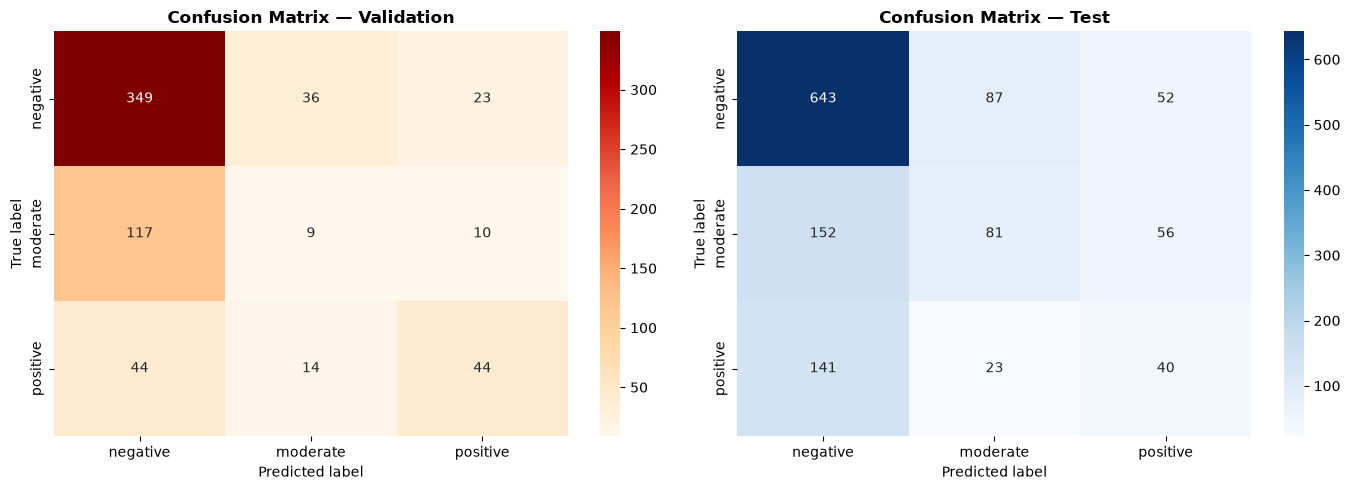

  FINAL ERROR REPORT — heterogeneous weighted ensemble v3
  Split          Samples         Loss     Accuracy        Error
  --------------------------------------------------------------------
  Training         5,066       0.0355     100.00%        0.00%
  Validation         646       0.8287      62.23%       37.77%
  Test             1,275       0.8830      59.92%       40.08%


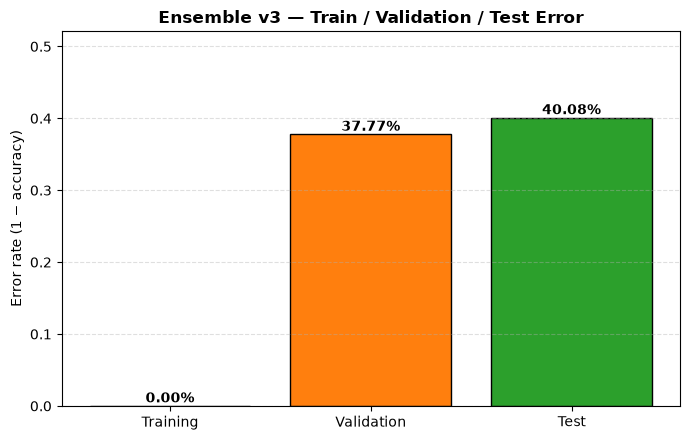

In [7]:
print('Test Set — Classification Report')
print('-' * 65)
print(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))
print('Real-only Test Set — Classification Report')
print('-' * 65)
print(classification_report(
    test_real_y, test_real_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))

classification_report_df = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0, output_dict=True
)).T
classification_report_path = OUTPUT_DIR / 'test_classification_report_ensemble_v3.csv'
classification_report_df.to_csv(classification_report_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, predictions, labels, title, colour_map in [
    (axes[0], val_predictions, y_val, 'Confusion Matrix — Validation', 'OrRd'),
    (axes[1], test_predictions, y_test, 'Confusion Matrix — Test', 'Blues'),
]:
    matrix = confusion_matrix(labels, predictions, labels=np.arange(len(CLASS_NAMES)))
    sns.heatmap(matrix, annot=True, fmt='d', cmap=colour_map,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
confusion_path = OUTPUT_DIR / 'confusion_matrices_ensemble_v3.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()

train_metrics = calculate_metrics(y_trainval, train_probabilities)
val_metrics = calculate_metrics(y_val, val_probabilities)
report_rows = [
    ('Training', len(y_trainval), train_metrics['log_loss'], train_metrics['accuracy']),
    ('Validation', len(y_val), val_metrics['log_loss'], val_metrics['accuracy']),
    ('Test', len(y_test), test_metrics['log_loss'], test_metrics['accuracy']),
]
print('=' * 74)
print('  FINAL ERROR REPORT — heterogeneous weighted ensemble v3')
print('=' * 74)
print(f'  {"Split":<12}{"Samples":>10}{"Loss":>13}{"Accuracy":>13}{"Error":>13}')
print('  ' + '-' * 68)
for split_name, count, loss_value, accuracy_value in report_rows:
    print(f'  {split_name:<12}{count:>10,}{loss_value:>13.4f}'
          f'{accuracy_value:>12.2%}{1-accuracy_value:>13.2%}')
print('=' * 74)

final_error_df = pd.DataFrame(report_rows, columns=['split', 'samples', 'loss', 'accuracy'])
final_error_df['error'] = 1 - final_error_df['accuracy']
final_error_csv = OUTPUT_DIR / 'final_error_report_ensemble_v3.csv'
final_error_df.to_csv(final_error_csv, index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(final_error_df['split'], final_error_df['error'],
              color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
for bar, error_rate in zip(bars, final_error_df['error']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{error_rate:.2%}', ha='center', fontweight='bold')
ax.set_ylabel('Error rate (1 − accuracy)')
ax.set_title('Ensemble v3 — Train / Validation / Test Error', fontweight='bold')
ax.set_ylim(0, max(final_error_df['error']) * 1.25 + 0.02)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
final_error_png = OUTPUT_DIR / 'final_error_report_ensemble_v3.png'
plt.savefig(final_error_png, dpi=150, bbox_inches='tight')
plt.show()

## 6. Misclassified image CSV files

In [8]:
def build_misclassified_table(labels, predictions, probabilities, groups, paths, split_name):
    rows = []
    for index in np.flatnonzero(predictions != labels):
        path = Path(paths[index])
        row = {
            'split': split_name, 'split_index': int(index), 'image_name': path.name,
            'image_path': str(path), 'image_id': int(groups[index]),
            'image_type': 'augmented' if is_augmented_path(path) else 'real',
            'true_label': CLASS_NAMES[int(labels[index])],
            'predicted_label': CLASS_NAMES[int(predictions[index])],
            'confidence': float(probabilities[index, predictions[index]]),
        }
        for class_index, class_name in enumerate(CLASS_NAMES):
            row[f'probability_{class_name}'] = float(probabilities[index, class_index])
        rows.append(row)
    return pd.DataFrame(rows)

val_misclassified_df = build_misclassified_table(
    y_val, val_predictions, val_probabilities, val_groups, val_paths, 'validation'
)
test_misclassified_df = build_misclassified_table(
    y_test, test_predictions, test_probabilities, test_groups, test_paths, 'test'
)
val_misclassified_df.to_csv(VAL_MISCLASSIFIED_CSV, index=False)
test_misclassified_df.to_csv(TEST_MISCLASSIFIED_CSV, index=False)
print(f'Validation errors: {len(val_misclassified_df):,}/{len(y_val):,} — {VAL_MISCLASSIFIED_CSV}')
print(f'Test errors      : {len(test_misclassified_df):,}/{len(y_test):,} — {TEST_MISCLASSIFIED_CSV}')
display(test_misclassified_df.head(30))

Validation errors: 244/646 — D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f3\val_misclassified_ensemble_v3.csv
Test errors      : 511/1,275 — D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f3\misclassified_images_ensemble_v3.csv


,split,split_index,image_name,image_path,image_id,image_type,true_label,predicted_label,confidence,probability_negative,probability_moderate,probability_positive
0,test,0,img114_autocontrast.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.551734,0.551734,0.342448,0.105818
1,test,1,img114_brightness_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.595517,0.595517,0.302063,0.102419
2,test,2,img114_brightness_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.696213,0.696213,0.214357,0.089430
3,test,3,img114_color_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.576215,0.576215,0.318015,0.105770
4,test,5,img114_contrast_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.548959,0.548959,0.352589,0.098451
5,test,6,img114_contrast_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.676958,0.676958,0.219130,0.103912
6,test,7,img114_edge_enhance.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.516338,0.516338,0.387398,0.096263
7,test,8,img114_equalize.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.706998,0.706998,0.193807,0.099195
8,test,9,img114_gaussian_blur.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.568193,0.568193,0.349660,0.082147
9,test,11,img114_grayscale_3ch.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,0.677114,0.677114,0.220861,0.102025


## 7. Bias–variance graph and ensemble weights

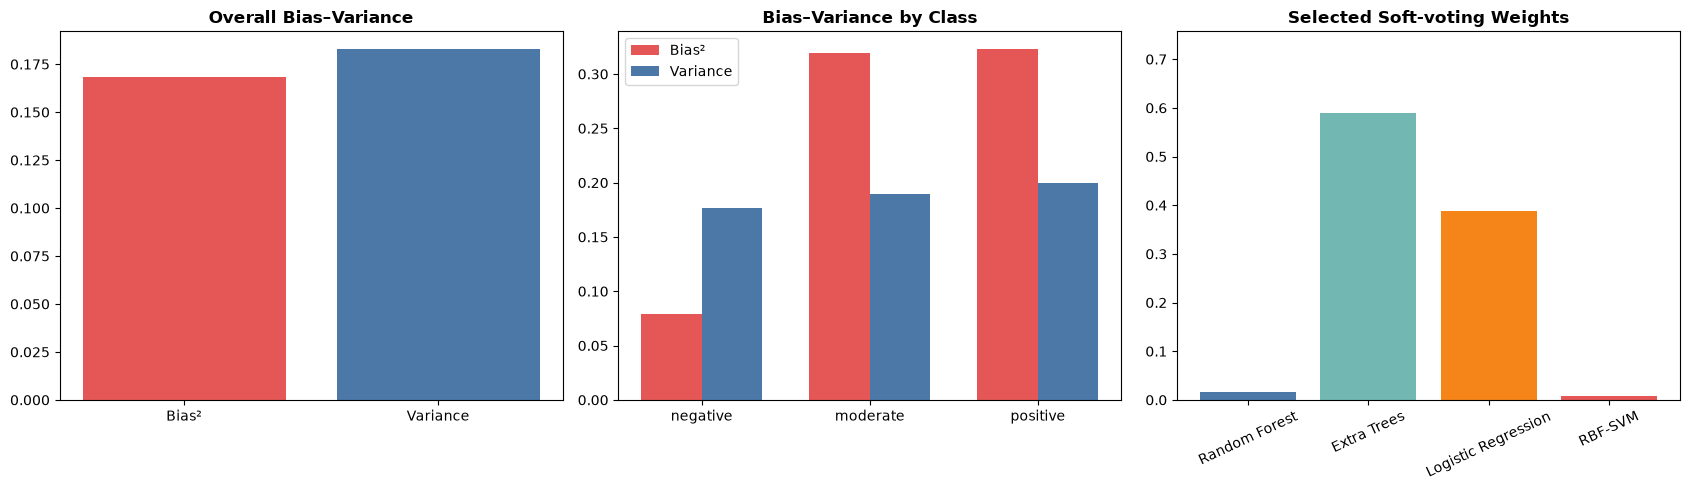

Bias²: 0.168489 | Variance: 0.182963
Graph saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f3\bias_variance_ensemble_v3.png


In [9]:
member_probabilities = bias_member_probabilities
member_weights = bias_member_weights
mean_probabilities = np.average(member_probabilities, axis=0, weights=member_weights)
one_hot = np.eye(len(CLASS_NAMES))[y_val]
bias_squared_samples = np.mean((mean_probabilities - one_hot) ** 2, axis=1)
tree_squared_distance = np.mean(
    (member_probabilities - mean_probabilities[None, :, :]) ** 2, axis=2
)
variance_samples = np.average(tree_squared_distance, axis=0, weights=member_weights)
overall_bias_squared = float(bias_squared_samples.mean())
overall_variance = float(variance_samples.mean())
class_bias = [bias_squared_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]
class_variance = [variance_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].bar(['Bias²', 'Variance'], [overall_bias_squared, overall_variance],
            color=['#e45756', '#4c78a8'])
axes[0].set_title('Overall Bias–Variance', fontweight='bold')
positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions-width/2, class_bias, width, label='Bias²', color='#e45756')
axes[1].bar(positions+width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias–Variance by Class', fontweight='bold')
axes[1].legend()
axes[2].bar([BASE_CONFIGS[key]['label'] for key in MODEL_KEYS], selected_weights,
            color=['#4c78a8', '#72b7b2', '#f58518', '#e45756'])
axes[2].set_title('Selected Soft-voting Weights', fontweight='bold')
axes[2].tick_params(axis='x', rotation=25)
axes[2].set_ylim(0, max(selected_weights) * 1.25 + 0.02)
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()
print(f'Bias²: {overall_bias_squared:.6f} | Variance: {overall_variance:.6f}')
print(f'Graph saved to: {BIAS_VARIANCE_PNG}')

## 8. Save the ensemble and inference helper

In [10]:
artifact = {
    'models': final_models,
    'active_keys': active_keys,
    'voting_weights': active_weights,
    'class_multipliers': selected_class_multipliers,
    'class_names': CLASS_NAMES,
    'backbone': BACKBONE_NAME,
    'feature_extractor': 'ImageNet pretrained ResNet50 V2, frozen 2048-D L2-normalized embedding',
    'test_metrics': test_metrics,
    'test_subject_metrics': test_subject_metrics,
    'test_real_metrics': test_real_metrics,
    'f2_reference': {
        'image_accuracy': REFERENCE_F2_IMAGE_ACCURACY,
        'image_macro_f1': REFERENCE_F2_IMAGE_MACRO_F1,
        'real_accuracy': REFERENCE_F2_REAL_ACCURACY,
        'real_macro_f1': REFERENCE_F2_REAL_MACRO_F1,
    },
}
with open(MODEL_PATH, 'wb') as file:
    pickle.dump(artifact, file)

performance_summary = pd.DataFrame([
    {'metric': 'image_accuracy', 'f2': REFERENCE_F2_IMAGE_ACCURACY,
     'f3': test_metrics['accuracy'], 'change': test_metrics['accuracy']-REFERENCE_F2_IMAGE_ACCURACY},
    {'metric': 'image_macro_f1', 'f2': REFERENCE_F2_IMAGE_MACRO_F1,
     'f3': test_metrics['macro_f1'], 'change': test_metrics['macro_f1']-REFERENCE_F2_IMAGE_MACRO_F1},
    {'metric': 'real_accuracy', 'f2': REFERENCE_F2_REAL_ACCURACY,
     'f3': test_real_metrics['accuracy'], 'change': test_real_metrics['accuracy']-REFERENCE_F2_REAL_ACCURACY},
    {'metric': 'real_macro_f1', 'f2': REFERENCE_F2_REAL_MACRO_F1,
     'f3': test_real_metrics['macro_f1'], 'change': test_real_metrics['macro_f1']-REFERENCE_F2_REAL_MACRO_F1},
])
performance_summary.to_csv(OUTPUT_DIR / 'f2_vs_f3_performance.csv', index=False)
display(performance_summary)
print(f'Model saved to: {MODEL_PATH}')

def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    with Image.open(image_path) as image:
        tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                embedding = resnet_backbone(tensor)
        else:
            embedding = resnet_backbone(tensor)
        embedding = F.normalize(embedding.float(), p=2, dim=1).cpu().numpy()
    probabilities = ensemble_predict_proba(
        trained_artifact['models'], trained_artifact['active_keys'],
        trained_artifact['voting_weights'], embedding,
        trained_artifact['class_multipliers'],
    )[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(
            trained_artifact['class_names'], probabilities.astype(float)
        )),
    }

# Example:
# trained_artifact = load_artifact()
# print(predict_image(PROJECT_ROOT / 'new_image.jpg', trained_artifact))

,metric,f2,f3,change
0,image_accuracy,0.6243,0.599216,-0.025084
1,image_macro_f1,0.3257,0.437773,0.112073
2,real_accuracy,0.5867,0.600000,0.013300
3,real_macro_f1,0.4644,0.433484,-0.030916


Model saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f3\rajuk_random_forest_ensemble_v3.pkl
